# Bước 5: Data Visualization
## Trực Quan Hóa Dữ Liệu Hành Vi Mua Hàng
---


## 5.0 Thiết Lập Thư Viện & Nạp Dữ Liệu Sạch (432.256 bản ghi)


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_path = Path('../Data/customerData_clean.csv') if Path('../Data/customerData_clean.csv').exists() else Path('Data/customerData_clean.csv')
df = pd.read_csv(data_path)
print(f"Số lượng bản ghi: {len(df):,}")


Số lượng bản ghi: 432,256


## 5.1 Biểu Đồ 1: Ma Trận Tương Quan


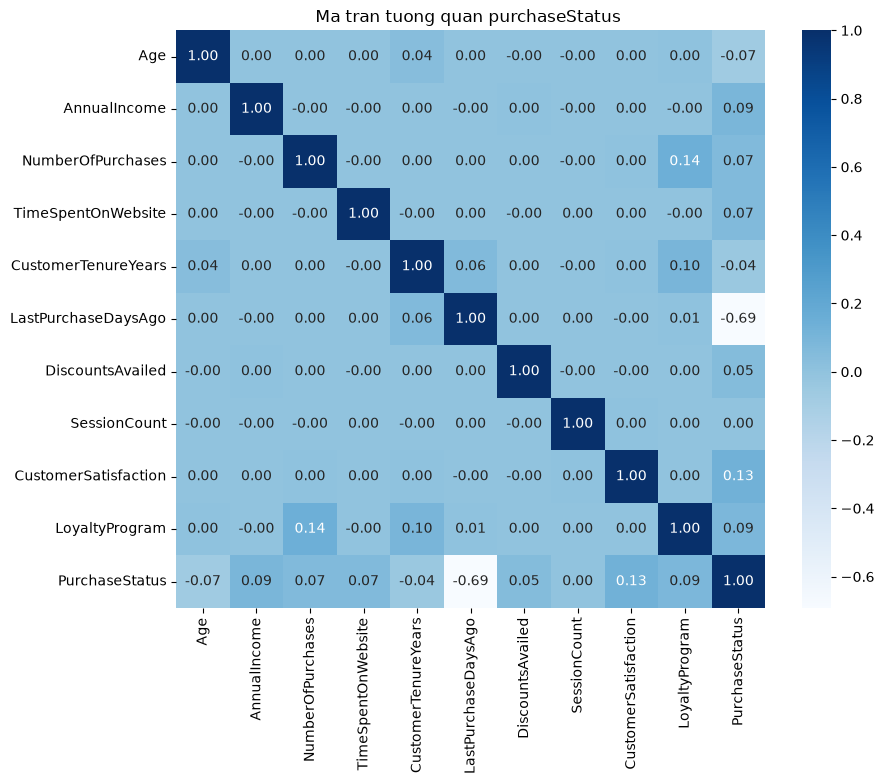

In [2]:

cols = ['Age', 'AnnualIncome', 'NumberOfPurchases', 'TimeSpentOnWebsite', 
            'CustomerTenureYears', 'LastPurchaseDaysAgo', 'DiscountsAvailed', 'SessionCount','CustomerSatisfaction','LoyaltyProgram',
            'PurchaseStatus']

corr_matrix = df[cols].corr()
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='Blues')
plt.title('Ma tran tuong quan purchaseStatus ')
plt.show()


1. Biến duy nhất có tương quan mạnh: LastPurchaseDaysAgo sở hữu tương quan âm mạnh (𝑟=−0.69) — độ trễ mua hàng càng xa thì khả năng chốt đơn càng giảm sút rõ rệt.
2. Các biến có tương quan dương nhưng ở mức yếu: AnnualIncome (+0.09 và LoyaltyProgram (+0.09) là hai yếu tố mang tương quan dương cao nhất thúc đẩy mua hàng, tuy nhiên độ lớn tương quan chỉ ở mức rất yếu (r<0.10).

3.Tính độc lập giữa các biến: Ngoại trừ đường chéo chính (= 1.00), toàn bộ các biến độc lập đều có tương quan chéo với nhau gần như bằng 0 (∣𝑟∣≤0.14) chứng minh dữ liệu hoàn toàn không bị hiện tượng đa cộng tuyến.

## 5.2 Biểu Đồ 2: Phân Phối Thời Gian Lướt Web


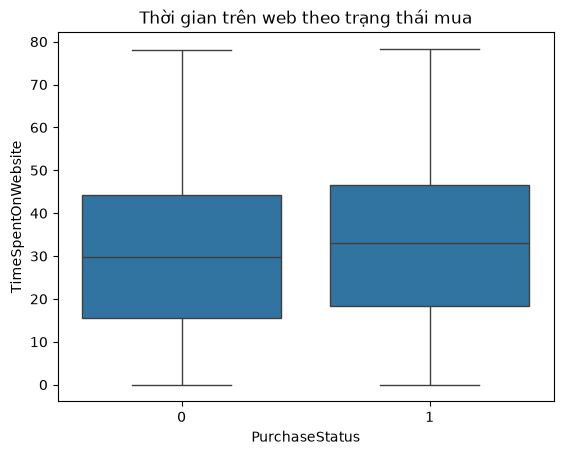

In [3]:
sns.boxplot(x='PurchaseStatus', y='TimeSpentOnWebsite', data=df)
plt.title('Thời gian trên web theo trạng thái mua')
plt.show()


Ý nghĩa: Thời gian lướt web chỉ là yếu tố bổ trợ nhẹ, khách vào lướt web hơn 30 phút vẫn có thể chỉ là ngắm dạo rồi thoát mà không mua.

## 5.3 Biểu Đồ 3: Tỷ Lệ Mua Theo Phân Khúc


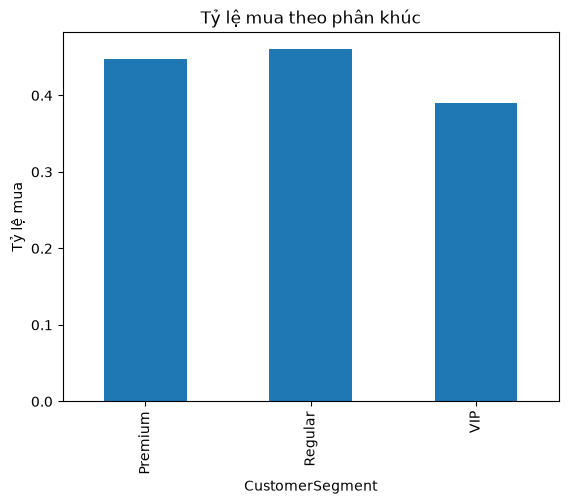

In [4]:
df.groupby('CustomerSegment')['PurchaseStatus'].mean().plot(kind='bar')
plt.title('Tỷ lệ mua theo phân khúc')
plt.ylabel('Tỷ lệ mua')
plt.show()


> **Đúc kết cốt lõi (Nghịch lý khách hàng VIP):** Phân khúc **Regular** (46.01%) và **Premium** (44.77%) có tỷ lệ chốt đơn cao hơn hẳn nhóm **VIP** (39.05%). Bằng chứng này khớp 100% với Truy vấn SQL 3 (File 3) và Kiểm định Chi-Square (File 4), chứng minh việc chỉ dựa vào nhãn VIP tĩnh để phân bổ nguồn lực tiếp thị là không hiệu quả.


## 5.4 Biểu Đồ 4: Tác Động & Ngưỡng Bão Hòa Của Mã Giảm Giá (DiscountsAvailed)


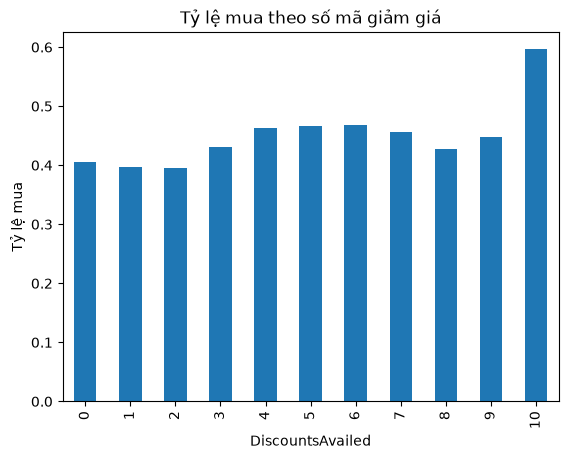

In [5]:
df.groupby('DiscountsAvailed')['PurchaseStatus'].mean().plot(kind='bar')
plt.title('Tỷ lệ mua theo số mã giảm giá')
plt.ylabel('Tỷ lệ mua')
plt.show()


> **Đúc kết cốt lõi (Điểm bão hòa Voucher):** Tỷ lệ chốt đơn tăng từ 40.54% (0 mã) lên đỉnh tại **5 mã giảm giá (46.72%)**. Từ mã thứ 6 trở đi, CVR đi ngang (46.77%) và có xu hướng giảm ở các mức mã cao hơn. Kết quả này khớp hoàn hảo với Truy vấn SQL 6 (Window Function LAG), xác lập quy tắc cứng cho Kịch bản 2 ở Bước 6: **Chặn tối đa không cấp quá 5 voucher/khách hàng** để tránh xói mòn biên lợi nhuận.


---
*Notebook tiếp theo: [6. Regression and Classification Analysis](./6.%20Regression%20and%20Classification%20Analysis.ipynb)*
